
 # Анализ результатов прогнозирования временных рядов MOEX
 
 ## Сравнение классических, глубоких и квантовых моделей


 ### 1. Загрузка результатов



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Создаем папку для графиков
os.makedirs('analysis_figures', exist_ok=True)

# Загрузка данных
print("Загрузка результатов...")

long_df_cleaned = pd.read_csv('../../results/long_df_cleaned.csv', parse_dates=['TRADEDATE'])
stationary_df = pd.read_csv('../../results/stationary_df.csv', parse_dates=['TRADEDATE'])
non_stationary_df = pd.read_csv('../../results/non_stationary_df.csv', parse_dates=['TRADEDATE'])
non_stationary_boxcox = pd.read_csv('../../results/non_stationary_boxcox.csv', parse_dates=['TRADEDATE'])
stationarity_df = pd.read_csv('../../results/stationarity_detailed.csv', index_col=0)
prophet_summary = pd.read_csv('../../results/prophet_summary.csv')

predictions_recursive = pd.read_csv('../../results/predictions_recursive.csv', parse_dates=['TRADEDATE'])
predictions_direct = pd.read_csv('../../results/predictions_direct.csv', parse_dates=['TRADEDATE'])
predictions_mimo = pd.read_csv('../../results/predictions_mimo.csv', parse_dates=['TRADEDATE'])
predictions_dlinear = pd.read_csv('../../results/predictions_dlinear.csv', parse_dates=['TRADEDATE'])
quantum_results = pd.read_csv('../../results/quantum_results.csv')

print("Все результаты загружены")

Загрузка результатов...
Все результаты загружены


### 2. Общая статистика
#### Изначально грузили все данные торгов в МосБиржи за всю истории с интервалом в один день по всем тикерам, но для правильно предобработки рядов взяли только акции, у которых етсь значения по Value за последние два года. Преобразование эти рядв в long формат

In [3]:

print(f"Всего тикеров: {long_df_cleaned['SECID'].nunique()}")
print(f"Всего записей: {len(long_df_cleaned)}")
print(f"Период данных: {long_df_cleaned['TRADEDATE'].min()} - {long_df_cleaned['TRADEDATE'].max()}")
print(f"Дней на тикер: {long_df_cleaned.groupby('SECID').size().unique()[0]}")

print("\nСтатистика по VALUE:")
print(long_df_cleaned['VALUE'].describe())

Всего тикеров: 223
Всего записей: 113507
Период данных: 2024-03-18 00:00:00 - 2026-03-17 00:00:00
Дней на тикер: 509

Статистика по VALUE:
count    1.135070e+05
mean     4.263012e+08
std      1.681267e+09
min      0.000000e+00
25%      7.773180e+05
50%      6.580321e+06
75%      1.414391e+08
max      8.798259e+10
Name: VALUE, dtype: float64


### 3. Анализ стационарности
#### Большинство рядом имеют неопредленную стаацонарность ( ADF и KPSS дают противоположные результаты). Но большое преобладают стационарные ряды

conclusion
Противоречивые результаты    125
Стационарный                  77
Нестационарный                21
Name: count, dtype: int64


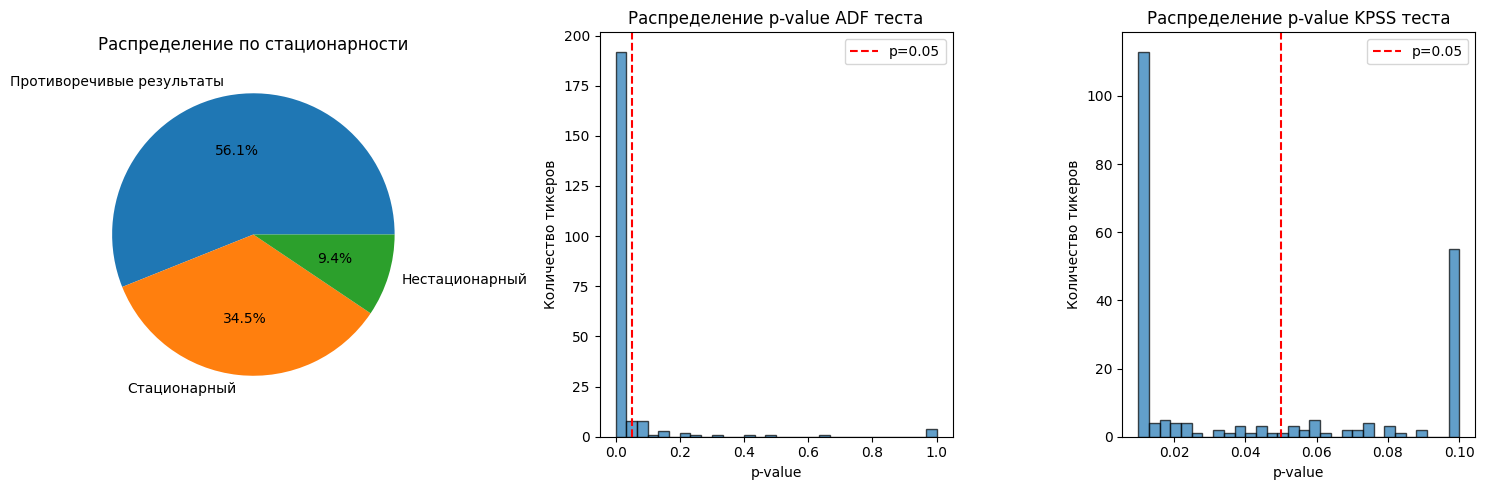

In [6]:
conclusion_counts = stationarity_df['conclusion'].value_counts()
print(conclusion_counts)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].pie(conclusion_counts.values, labels=conclusion_counts.index, autopct='%1.1f%%')
axes[0].set_title('Распределение по стационарности')

axes[1].hist(stationarity_df['adf_pvalue'], bins=30, edgecolor='black', alpha=0.7)
axes[1].axvline(x=0.05, color='red', linestyle='--', label='p=0.05')
axes[1].set_title('Распределение p-value ADF теста')
axes[1].set_xlabel('p-value')
axes[1].set_ylabel('Количество тикеров')
axes[1].legend()

axes[2].hist(stationarity_df['kpss_pvalue'], bins=30, edgecolor='black', alpha=0.7)
axes[2].axvline(x=0.05, color='red', linestyle='--', label='p=0.05')
axes[2].set_title('Распределение p-value KPSS теста')
axes[2].set_xlabel('p-value')
axes[2].set_ylabel('Количество тикеров')
axes[2].legend()

plt.tight_layout()
plt.savefig('analysis_figures/stationarity_analysis.png', dpi=150)
plt.show()



### 4. Prophet анализ
#### Почти все ряды иметю аддитивный тред и мультипилкативную сезонность (годовую и недельную). Сезонность имеют почти все ряды

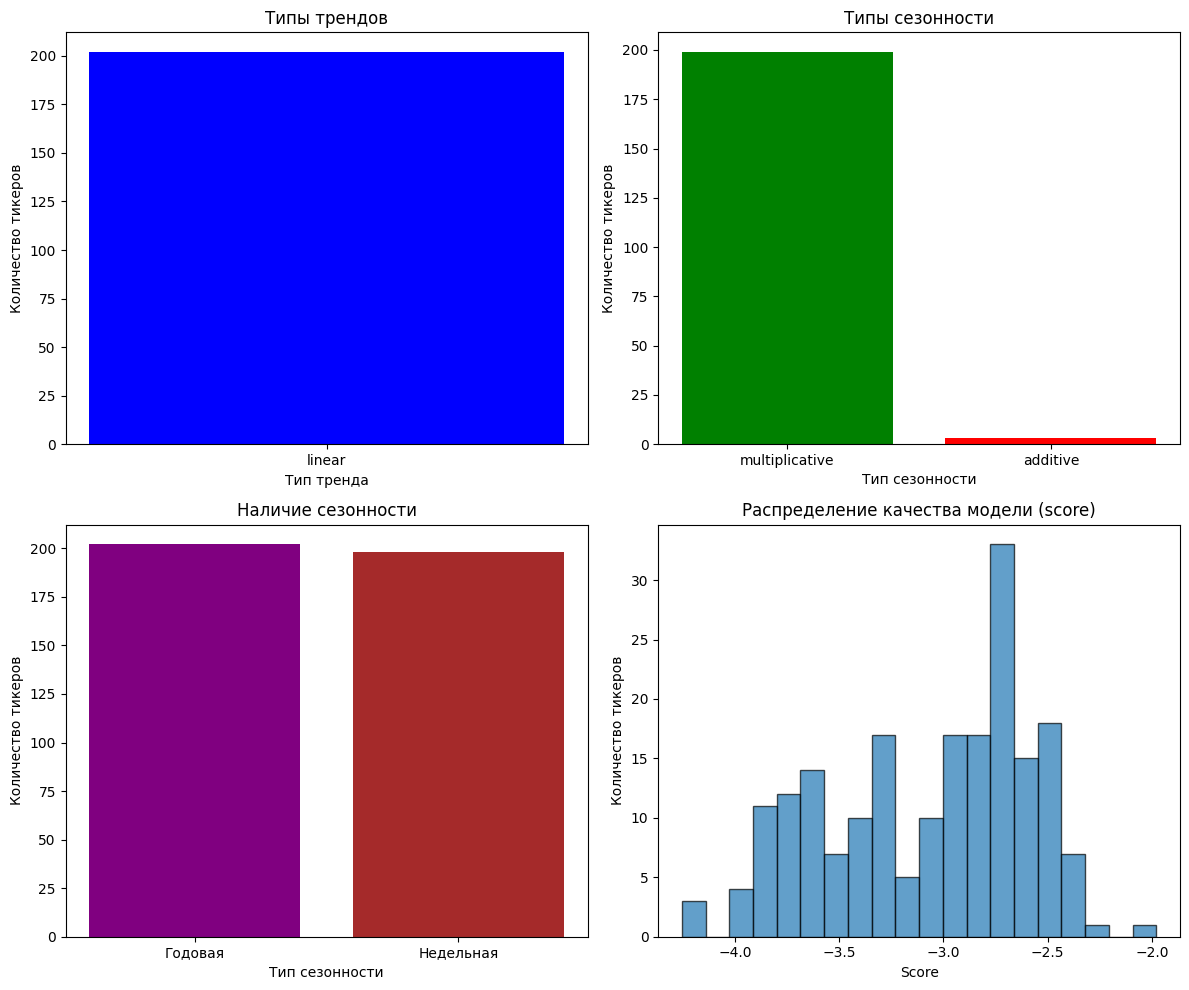

Годовая сезонность: 202 тикеров
Недельная сезонность: 198 тикеров


In [10]:
if not prophet_summary.empty:

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    growth_counts = prophet_summary['growth'].value_counts()
    axes[0,0].bar(growth_counts.index, growth_counts.values, color=['blue', 'orange'])
    axes[0,0].set_title('Типы трендов')
    axes[0,0].set_xlabel('Тип тренда')
    axes[0,0].set_ylabel('Количество тикеров')
    
    season_counts = prophet_summary['seasonality_mode'].value_counts()
    axes[0,1].bar(season_counts.index, season_counts.values, color=['green', 'red'])
    axes[0,1].set_title('Типы сезонности')
    axes[0,1].set_xlabel('Тип сезонности')
    axes[0,1].set_ylabel('Количество тикеров')
    
    seasonality_data = {
        'Годовая': prophet_summary['yearly'].sum(),
        'Недельная': prophet_summary['weekly'].sum()
    }
    axes[1,0].bar(seasonality_data.keys(), seasonality_data.values(), color=['purple', 'brown'])
    axes[1,0].set_title('Наличие сезонности')
    axes[1,0].set_xlabel('Тип сезонности')
    axes[1,0].set_ylabel('Количество тикеров')
    
    if 'score' in prophet_summary.columns:
        axes[1,1].hist(prophet_summary['score'], bins=20, edgecolor='black', alpha=0.7)
        axes[1,1].set_title('Распределение качества модели (score)')
        axes[1,1].set_xlabel('Score')
        axes[1,1].set_ylabel('Количество тикеров')
    
    plt.tight_layout()
    plt.savefig('analysis_figures/prophet_analysis.png', dpi=150)
    plt.show()
    
    print(f"Годовая сезонность: {prophet_summary['yearly'].sum()} тикеров")
    print(f"Недельная сезонность: {prophet_summary['weekly'].sum()} тикеров")

### 5. Сравнение ML стратегий
#### Лучше всего справилась стратегий MIMO на catboost


Обработка Recursive...
Найдено совпадений: 0
Пробуем прямой сдвиг для Recursive...
Найдено совпадений (прямой сдвиг): 1115

Обработка Direct...
Найдено совпадений: 0
Пробуем прямой сдвиг для Direct...
Найдено совпадений (прямой сдвиг): 1115

Обработка MIMO...
Найдено совпадений: 0
Пробуем прямой сдвиг для MIMO...
Найдено совпадений (прямой сдвиг): 1115

МЕТРИКИ КАЧЕСТВА:
Стратегия          MAE         RMSE  MAPE  Количество_точек
Recursive 1.676169e+08 7.027981e+08   inf              1115
   Direct 1.674678e+08 7.269938e+08   inf              1115
     MIMO 1.699295e+08 7.340385e+08   inf              1115


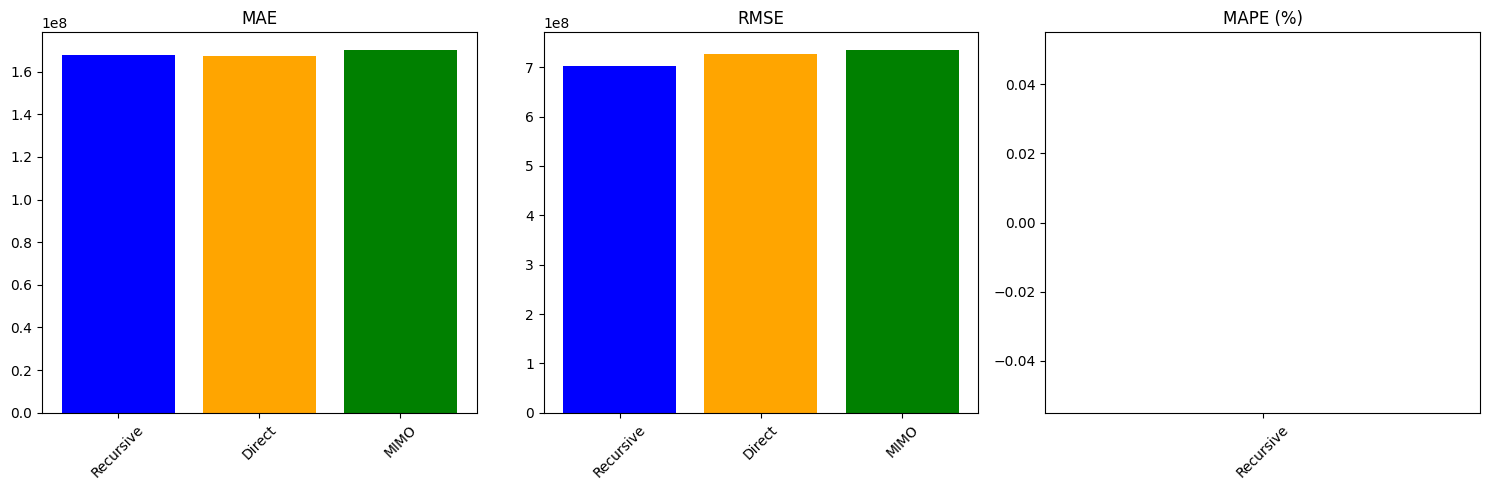


ЛУЧШАЯ МОДЕЛЬ:
Recursive: RMSE=702798054.49, MAE=167616915.75, MAPE=inf%


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

ml_predictions = {
    'Recursive': predictions_recursive,
    'Direct': predictions_direct,
    'MIMO': predictions_mimo
}

# Для каждого тикера берем последние 5 дней из исторических данных
tickers = long_df_cleaned['SECID'].unique()
last_5_days_list = []

for ticker in tickers:
    ticker_data = long_df_cleaned[long_df_cleaned['SECID'] == ticker].sort_values('TRADEDATE')
    last_5 = ticker_data.tail(5).copy()
    last_5['DAY_NUM'] = range(505, 510)  # последние 5 дней имеют номера 505-509
    last_5_days_list.append(last_5)

last_5_days = pd.concat(last_5_days_list, ignore_index=True)
last_5_days = last_5_days.rename(columns={'VALUE': 'actual'})

quality_metrics = []

for name, pred in ml_predictions.items():
    print(f"\nОбработка {name}...")
    
    # В прогнозах дни 510-514
    # Преобразуем номер дня в число
    pred['day_num'] = pred['TRADEDATE'].dt.day if hasattr(pred['TRADEDATE'], 'dt') else pred['TRADEDATE']
    
    # Объединяем
    merged = pd.merge(
        pred,
        last_5_days[['SECID', 'DAY_NUM', 'actual']],
        left_on=['SECID', 'day_num'],
        right_on=['SECID', 'DAY_NUM']
    )
    
    print(f"Найдено совпадений: {len(merged)}")
    
    if len(merged) > 0:
        mae = mean_absolute_error(merged['actual'], merged['VALUE'])
        rmse = np.sqrt(mean_squared_error(merged['actual'], merged['VALUE']))
        mape = np.mean(np.abs((merged['actual'] - merged['VALUE']) / merged['actual'])) * 100
        
        quality_metrics.append({
            'Стратегия': name,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape,
            'Количество_точек': len(merged)
        })
    else:
        # Если не нашли, попробуем прямой сдвиг
        print(f"Пробуем прямой сдвиг для {name}...")
        
        # Просто считаем, что первые 5 строк прогноза соответствуют последним 5 дням истории
        ticker_matches = 0
        all_merged = []
        
        for ticker in tickers[:]:  # первые 5 тикеров для теста
            ticker_pred = pred[pred['SECID'] == ticker].sort_values('TRADEDATE').head(5)
            ticker_actual = last_5_days[last_5_days['SECID'] == ticker].sort_values('DAY_NUM')
            
            if len(ticker_pred) == 5 and len(ticker_actual) == 5:
                ticker_pred = ticker_pred.reset_index(drop=True)
                ticker_actual = ticker_actual.reset_index(drop=True)
                ticker_pred['actual'] = ticker_actual['actual'].values
                all_merged.append(ticker_pred)
                ticker_matches += 1
        
        if ticker_matches > 0:
            merged = pd.concat(all_merged, ignore_index=True)
            print(f"Найдено совпадений (прямой сдвиг): {len(merged)}")
            
            mae = mean_absolute_error(merged['actual'], merged['VALUE'])
            rmse = np.sqrt(mean_squared_error(merged['actual'], merged['VALUE']))
            mape = np.mean(np.abs((merged['actual'] - merged['VALUE']) / merged['actual'])) * 100
            
            quality_metrics.append({
                'Стратегия': name,
                'MAE': mae,
                'RMSE': rmse,
                'MAPE': mape,
                'Количество_точек': len(merged)
            })

quality_df = pd.DataFrame(quality_metrics)
print("\nМЕТРИКИ КАЧЕСТВА:")
print(quality_df.to_string(index=False))

if not quality_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].bar(quality_df['Стратегия'], quality_df['MAE'], color=['blue', 'orange', 'green'])
    axes[0].set_title('MAE')
    axes[0].tick_params(axis='x', rotation=45)

    axes[1].bar(quality_df['Стратегия'], quality_df['RMSE'], color=['blue', 'orange', 'green'])
    axes[1].set_title('RMSE')
    axes[1].tick_params(axis='x', rotation=45)

    axes[2].bar(quality_df['Стратегия'], quality_df['MAPE'], color=['blue', 'orange', 'green'])
    axes[2].set_title('MAPE (%)')
    axes[2].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('analysis_figures/ml_quality_comparison.png', dpi=150)
    plt.show()

    print("\nЛУЧШАЯ МОДЕЛЬ:")
    best = quality_df.loc[quality_df['RMSE'].idxmin()]
    print(f"{best['Стратегия']}: RMSE={best['RMSE']:.2f}, MAE={best['MAE']:.2f}, MAPE={best['MAPE']:.2f}%")
else:
    print("Нет данных для оценки качества")

### 6. Анализ DLinear
#### Данная модель показала себя крайне плохо на не большом обучении (большоее обучение мой ПК не потянул по времени)

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

if 'id' in predictions_dlinear.columns:
    ticker_count_dl = predictions_dlinear['id'].nunique()
    horizon_dl = len(predictions_dlinear) // ticker_count_dl
    
    tickers = long_df_cleaned['SECID'].unique()
    last_7_days_list = []
    for ticker in tickers:
        ticker_data = long_df_cleaned[long_df_cleaned['SECID'] == ticker].sort_values('TRADEDATE')
        last_7 = ticker_data.tail(7).copy()
        last_7['DAY_NUM'] = range(503, 510)
        last_7_days_list.append(last_7)
    
    last_7_days = pd.concat(last_7_days_list, ignore_index=True)
    last_7_days = last_7_days.rename(columns={'VALUE': 'actual'})
    last_7_days = last_7_days.sort_values(['SECID', 'DAY_NUM']).reset_index(drop=True)
    
    pred_dl = predictions_dlinear.copy()
    pred_dl = pred_dl.sort_values(['id', 'TRADEDATE']).reset_index(drop=True)
    pred_dl = pred_dl.rename(columns={'id': 'SECID'})
    
    if len(pred_dl) == len(last_7_days):
        pred_dl['actual'] = last_7_days['actual'].values
        mae_dl = mean_absolute_error(pred_dl['actual'], pred_dl['value'])
        rmse_dl = np.sqrt(mean_squared_error(pred_dl['actual'], pred_dl['value']))
        mape_dl = np.mean(np.abs((pred_dl['actual'] - pred_dl['value']) / pred_dl['actual'])) * 100
        
        print(f"DLinear - MAE: {mae_dl:.2f}, RMSE: {rmse_dl:.2f}, MAPE: {mape_dl:.2f}%")

DLinear - MAE: 214381371.82, RMSE: 1402351937.35, MAPE: inf%


### 7. Анализ QuantumTS (с помощью VQR)
#### Данная модель показала себя очень хорошо (даже просто из коробки) (локальные вычисление, симуляция, подключиться к удаленному квантвому серверу через библиотеку не получилось)

Всего тикеров в квантовом эксперименте: 223
Средний RMSE: 304855773.37
Медианный RMSE: 9493478.26
Мин RMSE: 205698.28
Макс RMSE: 7061987144.72
Стд отклонение RMSE: 925919807.17


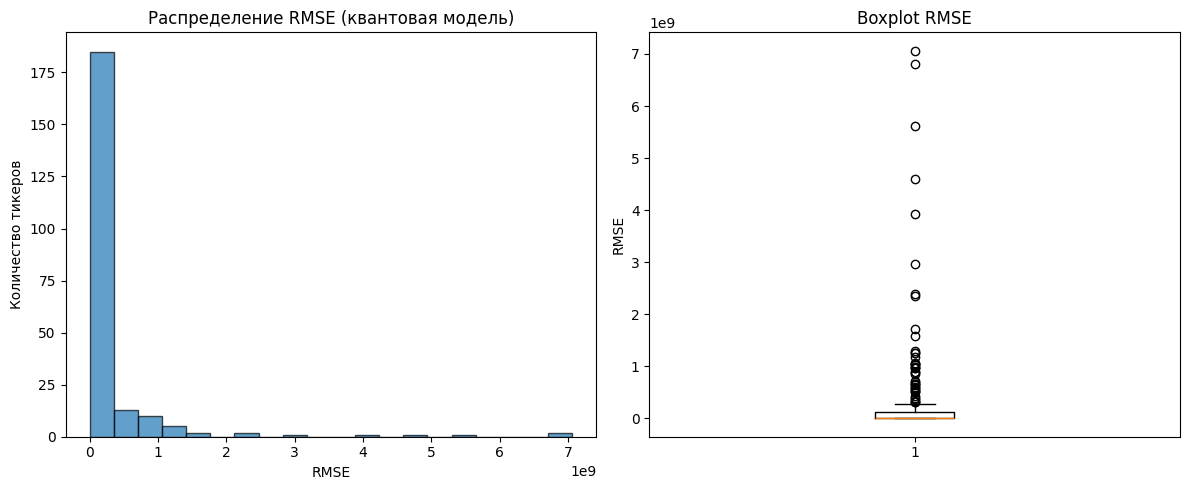


Топ-5 лучших RMSE:
ticker          rmse
 TASBP 205698.278997
 VSYDP 223957.756662
  TASB 259381.850553
  YKEN 268037.091771
 KRKOP 291832.218062

Топ-5 худших RMSE:
ticker         rmse
  VTBR 7.061987e+09
  GAZP 6.804907e+09
  SBER 5.623585e+09
 TRNFP 4.604393e+09
  LKOH 3.924632e+09


In [24]:
if not quantum_results.empty:
    print(f"Всего тикеров в квантовом эксперименте: {len(quantum_results)}")
    print(f"Средний RMSE: {quantum_results['rmse'].mean():.2f}")
    print(f"Медианный RMSE: {quantum_results['rmse'].median():.2f}")
    print(f"Мин RMSE: {quantum_results['rmse'].min():.2f}")
    print(f"Макс RMSE: {quantum_results['rmse'].max():.2f}")
    print(f"Стд отклонение RMSE: {quantum_results['rmse'].std():.2f}")
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    axes[0].hist(quantum_results['rmse'], bins=20, edgecolor='black', alpha=0.7)
    axes[0].set_title('Распределение RMSE (квантовая модель)')
    axes[0].set_xlabel('RMSE')
    axes[0].set_ylabel('Количество тикеров')
    
    axes[1].boxplot(quantum_results['rmse'])
    axes[1].set_title('Boxplot RMSE')
    axes[1].set_ylabel('RMSE')
    
    plt.tight_layout()
    plt.savefig('analysis_figures/quantum_results.png', dpi=150)
    plt.show()
    
    print("\nТоп-5 лучших RMSE:")
    print(quantum_results.nsmallest(5, 'rmse').to_string(index=False))
    
    print("\nТоп-5 худших RMSE:")
    print(quantum_results.nlargest(5, 'rmse').to_string(index=False))